# What Does a Stellar Occultation Do to an Asteroid's Orbit?

*Matthew Payne*

When an asteroid passes in front of a star, observers inside its shadow see the star blink out. The moment of disappearance and reappearance, timed to a fraction of a second and combined with the star's position from Gaia, locates the asteroid relative to the star to about a kilometre, or a few milliarcseconds: tens to hundreds of times better than an ordinary telescopic position (Rommel et al. 2020; Ferreira et al. 2022).

But an occultation measures only where the asteroid is *on the sky*, at one moment. What does one such measurement do to the uncertainty of the whole orbit, and to predictions of where the asteroid will be later? What does a second one add?

We will:

1. Ask how well the orbit of a numbered main-belt asteroid is known without occultations, and how that depends on how long it has been observed.
2. Simulate the observations of an asteroid like a typical numbered main-belt asteroid, with idealised, exactly known uncertainties, so that the geometry is not confused by the imperfections of real data.
3. Add one simulated occultation, and look at the cloud of possible positions from the side: collapsed on the sky, but how about along the line of sight?
4. Add a second occultation, two weeks or one year later, and follow the uncertainty forward in time.
5. Then turn to real data: test optical-only orbits of real asteroids against their real occultations, and see how much real uncertainties are underestimated.

This is the third notebook in a series on orbital uncertainty, after [NEOCP tracklets](../neocp_uncertainty/neocp_uncertainty.ipynb) and [the rise and fall of an impact probability](../impact_probability/impact_probability.ipynb). It uses the `orbunc` toolkit in this repository.

**Requirements:** as for the other notebooks in the series (`orbunc` with ASSIST and its ephemeris files).

**Run time:** about five minutes; a few minutes with `QUICK = True`.

In [1]:
import time
import warnings

import matplotlib.pyplot as plt
import numpy as np
from astropy.time import Time

from orbunc import ephem, fit, frames, mpc, predict, simulate
import occult   # helper module in this folder

QUICK = False
REAL = ["2000", "4000"] if QUICK else ["2000", "4000", "1000"]   # asteroids with real occultations (Part B)
rng = np.random.default_rng(4000)
KM, MAS = frames.AU_KM, frames.ARCSEC / 1e3
C4 = occult.STAGE_COLOURS
ephem.get_ephem()
warnings.filterwarnings("ignore", module="erfa")                       # future dates: UTC undefined, harmless here
warnings.filterwarnings("ignore", message=".*polar motion.*")          # Earth orientation beyond tabulated data
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

# Part A: an idealised asteroid

## 1. The asteroid, and how well its orbit is known

We take the orbit of the numbered main-belt asteroid (500000) as the *true* orbit of our idealised asteroid. Its observations, though, are simulated: on three nights around each opposition (10 days before, at, and 10 days after), a tracklet of three positions half an hour apart from the Mount Lemmon Survey (observatory code G96), taken when the asteroid is highest in a dark sky, each with independent Gaussian errors of exactly 0.3 arcsec. A least-squares fit to these observations then has a covariance that is right by construction.

How well is the orbit known? That depends on how long the asteroid has been observed. Here is the 1-sigma uncertainty of its position on 2027 January 1, along its track on the sky, across it, and along the line of sight from the Earth, for histories of 4 to 26 oppositions.

true orbit: a = 3.10 au, e = 0.039, i = 8.8 deg; H = 15.8, so a diameter of about 2.9 km for an albedo of 0.1


 4 oppositions (2023-2026):  36 positions, chi2/dof = 1.01; 1-sigma on 2027 Jan 1: along-track    5546 km, across   692 km, line of sight   4761 km


 8 oppositions (2019-2026):  72 positions, chi2/dof = 1.23; 1-sigma on 2027 Jan 1: along-track     145 km, across    77 km, line of sight     45 km


16 oppositions (2011-2026): 144 positions, chi2/dof = 0.84; 1-sigma on 2027 Jan 1: along-track     104 km, across    55 km, line of sight     30 km


26 oppositions (2001-2026): 234 positions, chi2/dof = 0.93; 1-sigma on 2027 Jan 1: along-track      77 km, across    41 km, line of sight     24 km
for comparison, one position good to 0.3 arcsec locates it to 860 km across the line of sight


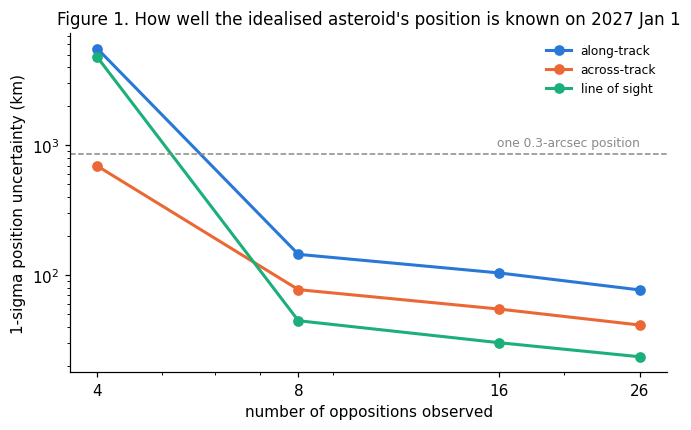

In [2]:
orb = mpc.fetch_orbit("500000", "data")
T_TRUE, X_TRUE, _ = mpc.orbit_state(orb)
H = orb["magnitude_data"]["H"]
D = simulate.diameter_km(H, albedo=0.1)
el = frames.elements(frames.bary_eq_to_helio_ec(X_TRUE[None], T_TRUE))
print(f"true orbit: a = {el['a'][0]:.2f} au, e = {el['e'][0]:.3f}, i = {el['i'][0]:.1f} deg; H = {H:.1f}, "
      f"so a diameter of about {D:.1f} km for an albedo of 0.1")

t_jan27 = Time("2027-01-01", scale="tdb").jd - ephem.JD_REF
histories = {4: range(2023, 2027), 8: range(2019, 2027), 16: range(2011, 2027), 26: range(2001, 2027)}
priors, rows = {}, []
for n, years in histories.items():
    O, f = occult.history_fit(X_TRUE, T_TRUE, years, "G96", 0.3, rng)
    priors[n] = (O, f)
    X, C = occult.propagate_cov(f.state, f.cov, f.t, [t_jan27])
    rows.append(occult.sigmas_km(X, C, [t_jan27])[0])
    print(f"{n:2d} oppositions ({years.start}-{years.stop - 1}): {len(O):3d} positions, chi2/dof = {f.chi2 / (2 * len(O) - 6):.2f}; "
          f"1-sigma on 2027 Jan 1: along-track {rows[-1][0]:7.0f} km, across {rows[-1][1]:5.0f} km, line of sight {rows[-1][2]:6.0f} km")
dist = np.linalg.norm(ephem.propagate(X_TRUE[None], T_TRUE, [t_jan27])[0, 0, :3] - ephem.body_state("earth", t_jan27)[0, :3]) * KM
print(f"for comparison, one position good to 0.3 arcsec locates it to {0.3 * frames.ARCSEC * dist:.0f} km across the line of sight")

rows = np.array(rows)
fig, ax = plt.subplots(figsize=(7, 4))
for j, (lab, c) in enumerate(zip(["along-track", "across-track", "line of sight"], C4)):
    ax.plot(list(histories), rows[:, j], "o-", color=c, lw=2, label=lab)
ax.axhline(0.3 * frames.ARCSEC * dist, color=occult.MUTED, ls="--", lw=1)
ax.text(26, 0.3 * frames.ARCSEC * dist * 1.15, "one 0.3-arcsec position", ha="right", fontsize=8, color=occult.MUTED)
ax.set_xscale("log"); ax.set_yscale("log")
ax.set_xticks(list(histories)); ax.set_xticklabels(list(histories))
ax.xaxis.set_minor_formatter(plt.NullFormatter())
ax.set_xlabel("number of oppositions observed")
ax.set_ylabel("1-sigma position uncertainty (km)")
ax.legend(fontsize=8, frameon=False)
ax.set_title("Figure 1. How well the idealised asteroid's position is known on 2027 Jan 1", fontsize=11)
plt.show()

With four oppositions, roughly when an asteroid becomes eligible for numbering, its position is uncertain by thousands of kilometres along its track and along the line of sight. With decades of observations the uncertainty falls to tens of kilometres, far below the uncertainty of any single observation, because the fit averages hundreds of them and the laws of motion connect them. (Real asteroids with long histories are known to tens of km too, but, as Part B shows, their formal uncertainties are optimistic.)

We follow two cases: a **short arc** (4 oppositions, 2023 to 2026) and a **long arc** (26 years, 2001 to 2026).

## 2. What an occultation measures

An occultation fixes the direction from an observer to the asteroid at the moment of the event, relative to the occulted star. The precision is different in two directions:

* **along the asteroid's track**, from the timing of the disappearance and reappearance: a timing error of 0.1 s, at a shadow speed of around 10 km/s, is about 1 km;
* **across the track**, from where the observer's chord crosses the asteroid's silhouette: with a single chord we know only that the chord passed somewhere within the asteroid's radius $R$ of its centre, an uncertainty of about $R/\sqrt3$; with many chords, much better.

The star's position adds a little (we take 0.3 mas for a Gaia star). We simulate a single-chord occultation observed from G96 near the asteroid's 2027 opposition, with 1 km along the track and $R/\sqrt{3}$ across it. (We do not require a real star to be there: the point is the measurement's geometry, not the event's prediction.)

In [3]:
R = D / 2
t_opp27 = simulate.opposition(X_TRUE, T_TRUE, 2027)
JD1, alt1 = simulate.best_time_from(X_TRUE, T_TRUE, t_opp27, "G96")
JD2_NEAR, _ = simulate.best_time_from(X_TRUE, T_TRUE, t_opp27 + 14, "G96")
JD2_FAR, _ = simulate.best_time_from(X_TRUE, T_TRUE, simulate.opposition(X_TRUE, T_TRUE, 2028), "G96")
occ = lambda jd: simulate.occultation(X_TRUE, T_TRUE, jd, "G96", 1.0, R / np.sqrt(3), 0.3, rng)
OCC1, OCC2_NEAR, OCC2_FAR = occ(JD1), occ(JD2_NEAR), occ(JD2_FAR)
for lab, o in [("occultation 1", OCC1), ("second, 14 days later", OCC2_NEAR), ("second, a year later", OCC2_FAR)]:
    print(f"{lab:22s}: {Time(o.jd_utc[0], format='jd').iso[:16]} UTC; uncertainty (RA cos Dec, Dec) = "
          f"({o.sig_ra[0] * 1e3:.2f}, {o.sig_dec[0] * 1e3:.2f}) mas, correlation {o.corr[0]:+.2f}")

occultation 1         : 2027-07-20 07:23 UTC; uncertainty (RA cos Dec, Dec) = (0.76, 0.66) mas, correlation -0.01
second, 14 days later : 2027-08-03 06:18 UTC; uncertainty (RA cos Dec, Dec) = (0.75, 0.65) mas, correlation -0.01
second, a year later  : 2028-10-18 06:43 UTC; uncertainty (RA cos Dec, Dec) = (0.71, 0.65) mas, correlation +0.11


## 3. One occultation

Each orbit estimate is a six-dimensional Gaussian: a best-fitting orbit and its covariance. Adding the occultation is a linear (Kalman) update of that Gaussian (`orbunc.fit.update`), which for uncertainties this small is equivalent to refitting all the observations; Part B checks this. To see what changes, we draw possible positions of the asteroid at the moment of the occultation, before and after, and look at them from two directions: **face on**, as seen from the Earth (along-track and across-track on the sky), and **side on** (along-track against the line of sight).

 4 oppositions: 1-sigma (along, across, line of sight) km: before [11068  4394  6335], after [  1.1   0.9 167. ]
26 oppositions: 1-sigma (along, across, line of sight) km: before [80 47 24], after [ 1.1  0.9 23.3]


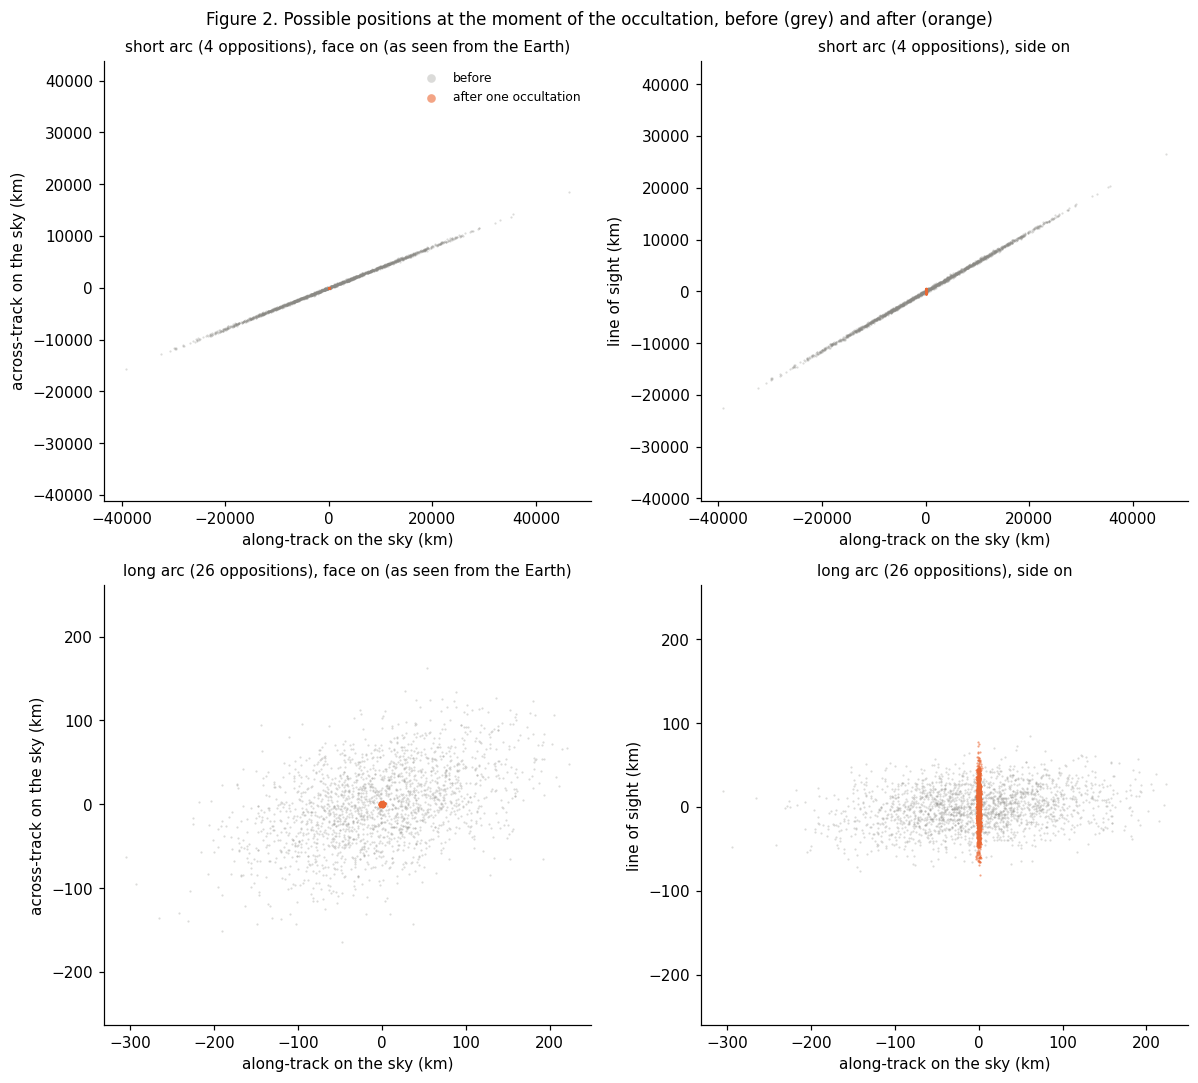

In [4]:
T1 = OCC1.t[0]
fig, axs = plt.subplots(2, 2, figsize=(11, 10))
for row, n in enumerate([4, 26]):
    O, f = priors[n]
    post = fit.update(f.state, f.cov, f.t, OCC1)
    before = occult.position_cloud(f.state, f.cov, f.t, T1, 2000, rng)
    after = occult.position_cloud(*post, f.t, T1, 2000, rng)
    for col, (j, lab) in enumerate([(1, "across-track on the sky (km)"), (2, "line of sight (km)")]):
        ax = axs[row, col]
        ax.scatter(before[:, 0], before[:, j], s=2, color=occult.MUTED, alpha=0.3, lw=0, rasterized=True, label="before")
        ax.scatter(after[:, 0], after[:, j], s=2, color=C4[1], alpha=0.6, lw=0, rasterized=True, label="after one occultation")
        ax.set_aspect("equal", adjustable="datalim")
        ax.set_xlabel("along-track on the sky (km)")
        ax.set_ylabel(lab)
        view = "face on (as seen from the Earth)" if col == 0 else "side on"
        ax.set_title(f"{'short' if n == 4 else 'long'} arc ({n} oppositions), {view}", fontsize=10)
    s0, s1 = before.std(0), after.std(0)
    print(f"{n:2d} oppositions: 1-sigma (along, across, line of sight) km: before {np.round(s0).astype(int)}, after {np.round(s1, 1)}")
axs[0, 0].legend(fontsize=8, frameon=False, markerscale=4)
fig.suptitle("Figure 2. Possible positions at the moment of the occultation, before (grey) and after (orange)", fontsize=11)
plt.tight_layout()
plt.show()

For the **long arc** the picture is exactly the intuitive one: the occultation collapses the cloud on the sky to about a kilometre, and leaves the line of sight untouched. Seen side on, a fuzzy blob becomes a needle pointing at the Earth.

For the **short arc** the occultation does more. A short arc's uncertainty is dominated by one direction in orbit space, the *line of variations*: the orbits that fit the observations form a long, thin family, and a position on the sky picks out where along that family the true orbit lies. So pinning the sky position at one moment also fixes most of the distance. The line of sight is no longer untouched, though much less well determined than the sky position.

## 4. A second occultation, and the uncertainty in time

An occultation pins the position at one moment. How long does that last? Here is the 1-sigma uncertainty from 2026 to 2031, before any occultation, after the first, and after a second one either 14 days or a year after the first. To follow it smoothly through time we now use the orbit's own directions: along the orbit, radially (towards or away from the Sun), and out of the orbital plane. (The view from the Earth swings around as the Earth and asteroid move, which would mix these.)

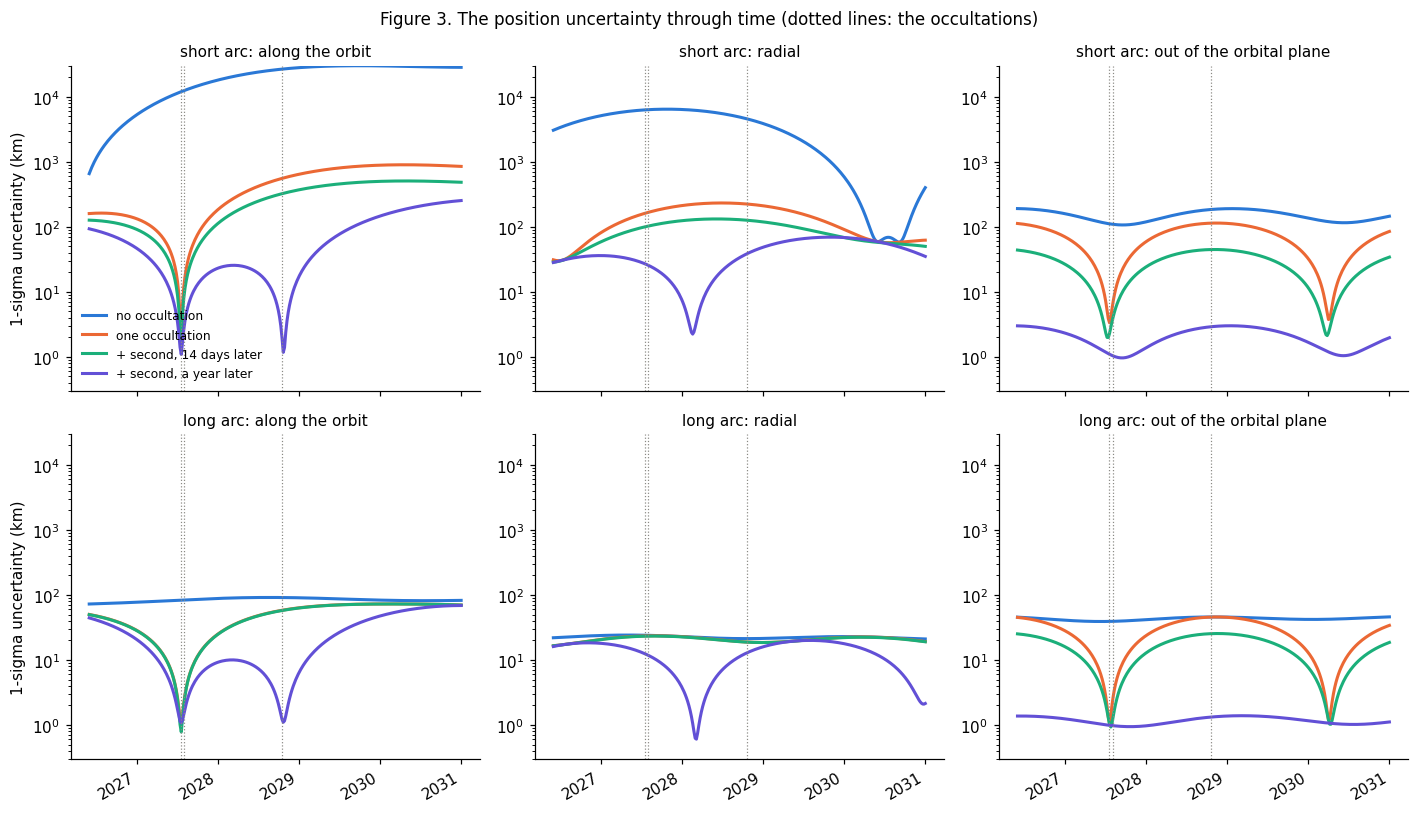

In [5]:
times = np.linspace(Time("2026-06-01").jd, Time("2031-01-01").jd, 300) - ephem.JD_REF
fig, axs = plt.subplots(2, 3, figsize=(13, 7.5), sharex=True)
dates = Time(times + ephem.JD_REF, format="jd").datetime
results = {}
for row, n in enumerate([4, 26]):
    O, f = priors[n]
    stages = {"no occultation": (f.state, f.cov)}
    stages["one occultation"] = fit.update(f.state, f.cov, f.t, OCC1)
    stages["+ second, 14 days later"] = fit.update(*stages["one occultation"], f.t, OCC2_NEAR)
    stages["+ second, a year later"] = fit.update(*stages["one occultation"], f.t, OCC2_FAR)
    for (lab, (x, C)), c in zip(stages.items(), C4):
        X, Cs = occult.propagate_cov(x, C, f.t, times)
        S = occult.sigmas_orbit_km(X, Cs, times)
        results[(n, lab)] = S
        for j in range(3):
            axs[row, j].plot(dates, S[:, j], color=c, lw=2, label=lab)
    for j, lab in enumerate(["along the orbit", "radial", "out of the orbital plane"]):
        ax = axs[row, j]
        ax.set_yscale("log")
        ax.set_ylim(0.3, 3e4)
        for o in (OCC1, OCC2_NEAR, OCC2_FAR):
            ax.axvline(Time(o.jd_utc[0], format="jd").datetime, color=occult.MUTED, lw=0.8, ls=":")
        ax.set_title(f"{'short' if n == 4 else 'long'} arc: {lab}", fontsize=10)
    axs[row, 0].set_ylabel("1-sigma uncertainty (km)")
axs[0, 0].legend(fontsize=8, frameon=False, loc="lower left")
fig.autofmt_xdate()
fig.suptitle("Figure 3. The position uncertainty through time (dotted lines: the occultations)", fontsize=11)
plt.tight_layout()
plt.show()

In [6]:
t_check = np.array([OCC2_FAR.t[0], Time("2030-06-01").jd - ephem.JD_REF])
for n in [4, 26]:
    print(f"{'short' if n == 4 else 'long'} arc: 1-sigma (along the orbit, radial, out of plane) km")
    for lab in ["no occultation", "one occultation", "+ second, 14 days later", "+ second, a year later"]:
        S = np.array([np.interp(t_check, times, results[(n, lab)][:, j]) for j in range(3)]).T
        print(f"   {lab:25s} at the 2028 opposition {np.round(S[0], 1)}   in mid-2030 {np.round(S[1], 1)}")

short arc: 1-sigma (along the orbit, radial, out of plane) km
   no occultation            at the 2028 opposition [26595.2  4580.9   184.3]   in mid-2030 [29073.6    59.1   115.4]
   one occultation           at the 2028 opposition [556.8 224.  113.6]   in mid-2030 [895.9  59.   20.5]
   + second, 14 days later   at the 2028 opposition [323.9 126.2  44.6]   in mid-2030 [505.5  57.5   9.4]
   + second, a year later    at the 2028 opposition [ 1.7 38.2  2.9]   in mid-2030 [199.2  58.9   1. ]
long arc: 1-sigma (along the orbit, radial, out of plane) km
   no occultation            at the 2028 opposition [91.2 21.3 45.8]   in mid-2030 [81.7 22.4 42.9]
   one occultation           at the 2028 opposition [58.3 18.9 45.7]   in mid-2030 [72.4 22.4  8.2]
   + second, 14 days later   at the 2028 opposition [57.8 18.8 25.4]   in mid-2030 [72.4 22.2  4.2]
   + second, a year later    at the 2028 opposition [ 1.2 12.8  1.3]   in mid-2030 [60.8 11.9  1. ]


Three things stand out.

* **The gain from one occultation fades.** Away from the moment of the event, the uncertainty along the orbit grows back, because the orbit's period is still uncertain and the error in where the asteroid is along its orbit accumulates. A year later, at the next opposition, one occultation has improved the long arc's prediction only modestly.
* **A second occultation helps only if it is well separated in time.** Two weeks later the asteroid has moved little along its orbit, and the second event measures nearly the same thing as the first. A year later it measures a different combination of the orbital elements, and the position at the 2028 opposition is pinned to about a kilometre on the sky.
* **Two occultations are not enough on their own.** Each one fixes two numbers (the position on the sky at one moment), and an orbit has six. With two events, two combinations of the orbital elements are still determined only by the ordinary observations; they show up as the uncertainty along the orbit growing again after 2028, and in the radial direction, which an occultation hardly sees. A third event, or many years of ordinary astrometry, fixes the rest.
* **Out of the orbital plane, the gain comes back.** After one occultation, the out-of-plane uncertainty returns to about a kilometre half an orbit later (around 2030.3; the orbital period is about 5.5 years). An error in the tilt of the orbit displaces the asteroid out of the plane by an amount that varies around the orbit, and is zero at the point the occultation pinned and half an orbit from it.

# Part B: real asteroids

## 5. How good are real orbits without occultations?

Real asteroid astrometry is not as tidy as our simulation: errors are not independent (they share star-catalogue and timing errors) and the stated uncertainties are often not right. Occultations offer a direct test. For a few numbered asteroids with several real occultations, we fit an orbit to the *optical* observations only (everything submitted before the first occultation was submitted; satellite observations, such as TESS and NEOWISE, are left out), predict where the asteroid should have been at each occultation, and compare with the occultation measurement (which is good to a few mas). The observations are weighted as in the [impact-probability notebook](../impact_probability/impact_probability.ipynb): a floor of 0.1 arcsec and down-weighting of large nightly batches.

As a check of the occultation measurements and of our handling of them, we also fit each asteroid to *all* its observations, occultations included: a consistent occultation should then fit to within its stated uncertainty.

In [7]:
real = {}
tic = time.time()
for desig in REAL:
    obs, sub, truth = occult.load(desig)
    st, occ = occult.stages(obs, sub, truth)
    base = obs.with_floor(0.1).deweight_nights()
    f_all = fit.fit_orbit_robust(st[0]["fit"].state, st[0]["fit"].t, base)
    z_all = obs.select(occ).whiten(predict.residuals(f_all.state[None], f_all.t, obs.select(occ)))[0]
    f0 = st[0]["fit"]
    miss, Cp = occult.sky_cov_mas(f0.state, f0.cov, f0.t, obs.select(occ))
    real[desig] = dict(obs=obs, occ=occ, stages=st, miss=miss, Cp=Cp, Co=[occult.occ_cov_mas(obs, k) for k in occ],
                       consistent=np.hypot(*z_all.T) < 3)
    for i, k in enumerate(occ):
        sig = np.sqrt(np.diag(Cp[i]))
        print(f"({desig}) occultation {Time(obs.jd_utc[k], format='jd').iso[:10]}: optical-only orbit misses by "
              f"({miss[i, 0]:+.1f}, {miss[i, 1]:+.1f}) mas; its formal 1-sigma is ({sig[0]:.1f}, {sig[1]:.1f}) mas; "
              f"with all data the occultation fits at {np.hypot(*z_all[i]):.1f} sigma")
print(f"[{time.time() - tic:.0f} s]")

(2000) occultation 2021-04-24: optical-only orbit misses by (-35.7, +46.7) mas; its formal 1-sigma is (7.7, 5.4) mas; with all data the occultation fits at 1.3 sigma
(2000) occultation 2024-03-20: optical-only orbit misses by (+9.3, +18.4) mas; its formal 1-sigma is (5.9, 5.7) mas; with all data the occultation fits at 1.3 sigma


(4000) occultation 2018-03-14: optical-only orbit misses by (-6.8, +16.2) mas; its formal 1-sigma is (8.5, 5.0) mas; with all data the occultation fits at 1.4 sigma
(4000) occultation 2021-10-08: optical-only orbit misses by (-0.7, +9.0) mas; its formal 1-sigma is (6.6, 5.1) mas; with all data the occultation fits at 1.4 sigma
(4000) occultation 2023-02-21: optical-only orbit misses by (-4.5, +8.0) mas; its formal 1-sigma is (7.1, 5.6) mas; with all data the occultation fits at 1.3 sigma


(1000) occultation 2016-12-28: optical-only orbit misses by (-3.0, -7.9) mas; its formal 1-sigma is (8.7, 5.9) mas; with all data the occultation fits at 5.4 sigma
(1000) occultation 2019-07-02: optical-only orbit misses by (-30.3, +47.0) mas; its formal 1-sigma is (9.2, 7.3) mas; with all data the occultation fits at 3.2 sigma
(1000) occultation 2022-02-06: optical-only orbit misses by (+13.4, -2.1) mas; its formal 1-sigma is (4.0, 4.1) mas; with all data the occultation fits at 0.9 sigma
(1000) occultation 2022-12-20: optical-only orbit misses by (+16.3, -6.6) mas; its formal 1-sigma is (6.9, 6.3) mas; with all data the occultation fits at 0.8 sigma
(1000) occultation 2025-08-03: optical-only orbit misses by (+23.4, +1.7) mas; its formal 1-sigma is (21.1, 11.0) mas; with all data the occultation fits at 1.3 sigma
[269 s]


using the 8 occultations consistent with their asteroid's full fit: the formal uncertainties of the optical-only orbits must be multiplied by about 2.5 to account for the misses


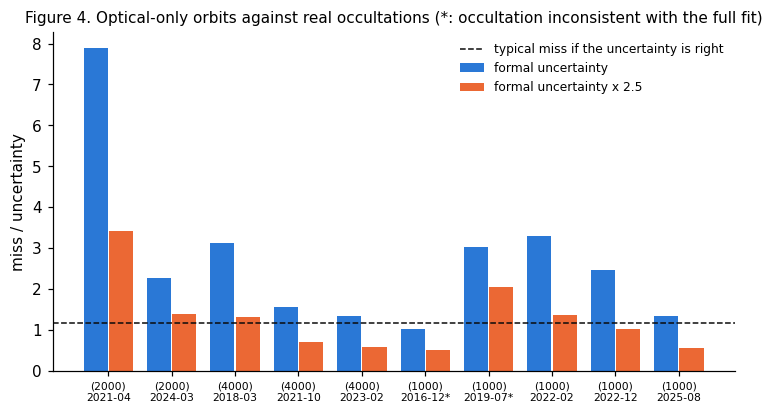

In [8]:
d_all, cp_all, co_all = [], [], []
for desig, r in real.items():
    for i in np.where(r["consistent"])[0]:
        d_all.append(r["miss"][i]); cp_all.append(r["Cp"][i]); co_all.append(r["Co"][i])
K = occult.inflation_factor(d_all, cp_all, co_all)
print(f"using the {len(d_all)} occultations consistent with their asteroid's full fit: the formal uncertainties of the "
      f"optical-only orbits must be multiplied by about {K:.1f} to account for the misses")

fig, ax = plt.subplots(figsize=(8, 4))
labels, z_formal, z_infl = [], [], []
for desig, r in real.items():
    for i, k in enumerate(r["occ"]):
        d, Cp, Co = r["miss"][i], r["Cp"][i], r["Co"][i]
        z_formal.append(np.sqrt(d @ np.linalg.solve(Cp + Co, d)))
        z_infl.append(np.sqrt(d @ np.linalg.solve(K * K * Cp + Co, d)))
        labels.append(f"({desig})\n{Time(r['obs'].jd_utc[k], format='jd').iso[:7]}" + ("" if r["consistent"][i] else "*"))
x = np.arange(len(labels))
ax.bar(x - 0.2, z_formal, 0.38, color=C4[0], label="formal uncertainty")
ax.bar(x + 0.2, z_infl, 0.38, color=C4[1], label=f"formal uncertainty x {K:.1f}")
ax.axhline(np.sqrt(2 * np.log(2)), color=occult.INK, lw=1, ls="--", label="typical miss if the uncertainty is right")
ax.set_xticks(x); ax.set_xticklabels(labels, fontsize=7)
ax.set_ylabel("miss / uncertainty")
ax.legend(fontsize=8, frameon=False)
ax.set_title("Figure 4. Optical-only orbits against real occultations (*: occultation inconsistent with the full fit)", fontsize=10)
plt.show()

The optical-only orbits predict the occultations to tens of mas, so tens of kilometres, but typically miss by two or three times their formal uncertainty, and sometimes by much more. The formal uncertainty assumes the errors of thousands of optical observations are independent, so that they average down; in reality many share errors (from the star catalogue in a patch of sky, the timing, the measurement method), which do not average down. The occultations themselves fit the full orbit within their uncertainties (apart from the starred ones, which disagree with the other data and would need a closer look), so the problem lies with the optical prior, not with the occultations.

## 6. (4000) Hipparchus, one occultation at a time

(4000) Hipparchus has three real occultations (2018 March, 2021 October and 2023 February; all three reached the MPC together, in 2024 January). As in Part A, we add them one at a time to the optical-only orbit, first with its formal covariance and then with the covariance inflated by the factor just found, and ask how well each stage predicts the *next* occultation.

In [9]:
r = real["4000"]
obs, occ, st = r["obs"], r["occ"], r["stages"]
f0 = st[0]["fit"]
print(f"check: adding the occultations by linear update reproduces the refits to "
      f"{max(np.max(np.abs(fit.update(f0.state, f0.cov, f0.t, obs.select(occ[:k]))[0] - st[k]['fit'].state) / np.sqrt(np.diag(st[k]['fit'].cov))) for k in (1, 2, 3)):.2f} sigma\n")
for name, scale in [("formal", 1.0), (f"inflated x {K:.1f}", K)]:
    x, C = f0.state, f0.cov * scale ** 2
    print(f"{name} prior:")
    for k in range(len(occ)):
        nxt = obs.select([occ[k]])
        miss, Cp = occult.sky_cov_mas(x, C, f0.t, nxt)
        d = miss[0]
        z = np.sqrt(d @ np.linalg.solve(Cp[0] + r["Co"][k], d))
        print(f"   with {k} occultation(s): predicts the next one ({Time(obs.jd_utc[occ[k]], format='jd').iso[:10]}) with 1-sigma "
              f"({np.sqrt(Cp[0][0, 0]):.1f}, {np.sqrt(Cp[0][1, 1]):.1f}) mas; actual miss ({d[0]:+.1f}, {d[1]:+.1f}) mas = {z:.1f} sigma")
        x, C = fit.update(x, C, f0.t, nxt)

check: adding the occultations by linear update reproduces the refits to 0.04 sigma

formal prior:
   with 0 occultation(s): predicts the next one (2018-03-14) with 1-sigma (8.5, 5.0) mas; actual miss (-6.8, +16.2) mas = 3.1 sigma
   with 1 occultation(s): predicts the next one (2021-10-08) with 1-sigma (5.6, 4.6) mas; actual miss (+2.6, +3.1) mas = 0.6 sigma


   with 2 occultation(s): predicts the next one (2023-02-21) with 1-sigma (6.9, 3.8) mas; actual miss (-6.0, +4.8) mas = 1.1 sigma
inflated x 2.5 prior:
   with 0 occultation(s): predicts the next one (2018-03-14) with 1-sigma (21.1, 12.5) mas; actual miss (-6.8, +16.2) mas = 1.3 sigma
   with 1 occultation(s): predicts the next one (2021-10-08) with 1-sigma (13.7, 11.4) mas; actual miss (+3.0, +2.5) mas = 0.3 sigma
   with 2 occultation(s): predicts the next one (2023-02-21) with 1-sigma (17.0, 7.1) mas; actual miss (-6.4, +4.4) mas = 0.5 sigma


With the formal prior, the first prediction misses by about three sigma, as Section 5 found. Once one occultation has been included, the later events are predicted within their uncertainties: the occultation has replaced the optical data's unreliable constraint on the sky position with a reliable one. With the inflated prior every prediction is consistent with its uncertainty, but the uncertainties stay about two and a half times larger, even after two occultations: as Part A showed, each occultation fixes only part of the orbit, and the rest still rests on the optical data. Which prior is right? The test against real occultations says the inflated one.

## 7. Summary

* Without occultations, a numbered main-belt asteroid observed for decades is located to tens of km, far better than any single observation, because thousands of observations are averaged; one observed at only a few oppositions is uncertain by thousands of km.
* An occultation fixes the position on the sky at one moment to about a kilometre. For a long-arc orbit it leaves the distance along the line of sight untouched; for a short-arc orbit it constrains that too, through the line of variations.
* The benefit fades with time, as the along-track uncertainty regrows. A second occultation helps a great deal if it is well separated in time (here a year), and little if it is not (two weeks). Each occultation fixes two of the six orbital elements; three, or a long optical history, are needed for the rest.
* Real optical-only orbits miss real occultations by typically two or three times their formal uncertainties (by a factor of 2.5 for the asteroids here), because optical errors are correlated. Occultations are valuable not only for their precision but because their errors are understood.

## 8. Going further

* **Multi-chord events.** Replace $R/\sqrt3$ across the track by a smaller value, as for a well-observed event with many chords, and see Figure 2 tighten across the track too.
* **A bigger or smaller asteroid.** Change the albedo or the true orbit (any designation in `mpc.fetch_orbit`).
* **Predicting real events.** The uncertainty perpendicular to the shadow's motion, at the time of a future event, is the uncertainty in where its path crosses the Earth; `occult.sigmas_km` gives it, in the view from the Earth, at any time.
* **Next in this series:** the Nancy Grace Roman Space Telescope's observations of distant objects towards the Galactic bulge, and how their uncertainty spreads out when seen from Roman and from the ground.

## References

* Carpino, M., Milani, A. & Chesley, S. R. (2003), *Error statistics of asteroid optical astrometric observations*, Icarus 166, 248. [ADS](https://ui.adsabs.harvard.edu/abs/2003Icar..166..248C/abstract)
* Desmars, J., Camargo, J. I. B., Braga-Ribas, F., et al. (2015), *Orbit determination of trans-Neptunian objects and Centaurs for the prediction of stellar occultations*, A&A 584, A96. [ADS](https://ui.adsabs.harvard.edu/abs/2015A%26A...584A..96D/abstract)
* Ferreira, J. F., Tanga, P., Spoto, F., et al. (2022), *Asteroid astrometry by stellar occultations: Accuracy of the existing sample from orbital fitting*, A&A 658, A73. [ADS](https://ui.adsabs.harvard.edu/abs/2022A%26A...658A..73F/abstract)
* Gaia Collaboration, Vallenari, A., Brown, A. G. A., et al. (2023), *Gaia Data Release 3: Summary of the content and survey properties*, A&A 674, A1. [ADS](https://ui.adsabs.harvard.edu/abs/2023A%26A...674A...1G/abstract)
* Holman, M. J., Akmal, A., Farnocchia, D., et al. (2023), *ASSIST: An Ephemeris-quality Test-particle Integrator*, PSJ 4, 69. [ADS](https://ui.adsabs.harvard.edu/abs/2023PSJ.....4...69H/abstract)
* Rommel, F. L., Braga-Ribas, F., Desmars, J., et al. (2020), *Stellar occultations enable milliarcsecond astrometry for Trans-Neptunian objects and Centaurs*, A&A 644, A40. [ADS](https://ui.adsabs.harvard.edu/abs/2020A%26A...644A..40R/abstract)
* Sicardy, B., Braga-Ribas, F., Buie, M. W., et al. (2024), *Stellar occultations by trans-Neptunian objects*, A&ARv 32, 6. [ADS](https://ui.adsabs.harvard.edu/abs/2024A%26ARv..32....6S/abstract)
* Vereš, P., Farnocchia, D., Chesley, S. R. & Chamberlin, A. B. (2017), *Statistical analysis of astrometric errors for the most productive asteroid surveys*, Icarus 296, 139. [ADS](https://ui.adsabs.harvard.edu/abs/2017Icar..296..139V/abstract)

Observations and orbits: the Minor Planet Center's public APIs; occultation astrometry as reported to the MPC in ADES format.